In [1]:
import pandas as pd 
import os

def get_data():
    path = "results/"
    filelist = os.listdir(path)
    data = []
    for i in filelist:
        if i.endswith(".csv"):
            df = pd.read_csv(path + i)
            data.append(df)
    return data 

In [2]:
data_list = []
for i in range(0,14):
    data_list.append(get_data()[i])

In [3]:
data_list[0].head()

,sim,comm_mode,winner,personality,role,survived,vote_correct,voted_for_role
0,1,clue_and_statement,civilian,aggressive,spy,0,0,civilian
1,1,clue_and_statement,civilian,deceptive,civilian,0,0,civilian
2,1,clue_and_statement,civilian,aggressive,civilian,0,0,civilian
3,1,clue_and_statement,civilian,conservative,spy,0,0,civilian
4,1,clue_and_statement,civilian,deceptive,civilian,1,0,civilian


# Combine the data

In [4]:
personality = pd.concat([data_list[0], data_list[1]], axis=0)

In [5]:
personality.head()

,sim,comm_mode,winner,personality,role,survived,vote_correct,voted_for_role
0,1,clue_and_statement,civilian,aggressive,spy,0,0,civilian
1,1,clue_and_statement,civilian,deceptive,civilian,0,0,civilian
2,1,clue_and_statement,civilian,aggressive,civilian,0,0,civilian
3,1,clue_and_statement,civilian,conservative,spy,0,0,civilian
4,1,clue_and_statement,civilian,deceptive,civilian,1,0,civilian


In [6]:
print(personality.shape)
print(data_list[0].shape)
print(data_list[1].shape)

(5473, 8)
(2705, 8)
(2768, 8)


In [7]:
rounds = pd.concat([data_list[6], data_list[7]], axis=0)

In [8]:
rounds.head()

,sim,round,comm_mode,player,role,personality,word,clue,statement,voted_for,vote_correct,eliminated,eliminated_role,winner
0,1,1,clue_and_statement,A1,spy,aggressive,Burger,Ketchup,You're probably trying to distract us from the...,A3,0,A3,civilian,civilian
1,1,1,clue_and_statement,A2,civilian,deceptive,Pizza,Crust,"I think A5 is a strong contender, but I'm not ...",A3,0,A3,civilian,civilian
2,1,1,clue_and_statement,A4,spy,conservative,Burger,Patty,"The mention of ""Patty"" seems unusual in this c...",A6,0,A3,civilian,civilian
3,1,1,clue_and_statement,A5,civilian,deceptive,Pizza,Topping,"I think the conversation is about food, not wh...",A8,0,A3,civilian,civilian
4,1,1,clue_and_statement,A6,civilian,aggressive,Pizza,Flour,"I'm suspicious of you, considering the ""Flour""...",A7,0,A3,civilian,civilian


In [9]:
print(rounds.shape)
print(data_list[6].shape)
print(data_list[7].shape)

(4840, 14)
(2399, 14)
(2441, 14)


In [10]:
spy = pd.concat([data_list[12], data_list[13]], axis=0)
spy.head()

,sim,comm_mode,winner,spy_name,personality,survival_time,elimination_round,caught
0,1,clue_and_statement,civilian,A1,aggressive,4,5.0,1
1,1,clue_and_statement,civilian,A4,conservative,1,2.0,1
2,2,clue_and_statement,spy,A5,conservative,1,2.0,1
3,2,clue_and_statement,spy,A8,aggressive,6,NaN,0
4,3,clue_and_statement,civilian,A4,deceptive,4,5.0,1


In [11]:
print(spy.shape)
print(data_list[12].shape)
print(data_list[13].shape)

(400, 8)
(200, 8)
(200, 8)


# Compute final personality metrics

## Personality Vote Accuracy Rate

In [12]:
personality.head()

,sim,comm_mode,winner,personality,role,survived,vote_correct,voted_for_role
0,1,clue_and_statement,civilian,aggressive,spy,0,0,civilian
1,1,clue_and_statement,civilian,deceptive,civilian,0,0,civilian
2,1,clue_and_statement,civilian,aggressive,civilian,0,0,civilian
3,1,clue_and_statement,civilian,conservative,spy,0,0,civilian
4,1,clue_and_statement,civilian,deceptive,civilian,1,0,civilian


In [13]:
personality_stats = {
    "aggressive": {"correct": 0, "total": 0},
    "conservative": {"correct": 0, "total": 0},
    "deceptive": {"correct": 0, "total": 0},
}

for index, row in personality.iterrows():
    personality_type = row["personality"]
    correct = row["vote_correct"]
    
    if personality_type in personality_stats:
        personality_stats[personality_type]["total"] += 1
        if correct:
            personality_stats[personality_type]["correct"] += 1

print(personality_stats)
    

{'aggressive': {'correct': 487, 'total': 1858}, 'conservative': {'correct': 434, 'total': 1770}, 'deceptive': {'correct': 481, 'total': 1845}}


In [14]:
aggressive_accuracy = personality_stats["aggressive"]["correct"] / personality_stats["aggressive"]["total"] if personality_stats["aggressive"]["total"] > 0 else 0
conservative_accuracy = personality_stats["conservative"]["correct"] / personality_stats["conservative"]["total"] if personality_stats["conservative"]["total"] > 0 else 0
deceptive_accuracy = personality_stats["deceptive"]["correct"] / personality_stats["deceptive"]["total"] if personality_stats["deceptive"]["total"] > 0 else 0
print(f"Aggressive Accuracy: {aggressive_accuracy:.2%}")
print(f"Conservative Accuracy: {conservative_accuracy:.2%}")
print(f"Deceptive Accuracy: {deceptive_accuracy:.2%}")
                                                                                                         

Aggressive Accuracy: 26.21%
Conservative Accuracy: 24.52%
Deceptive Accuracy: 26.07%


## Personality Survival Rate

In [15]:
survival_stats = {
    "aggressive" : {"survived": 0, "total": 0},
    "conservative": {"survived": 0, "total": 0},
    "deceptive": {"survived": 0, "total": 0},
}

for index, row in personality.iterrows():
    personality_type = row["personality"]
    survived = row["survived"]

    if personality_type in survival_stats:
        survival_stats[personality_type]["total"] += 1
        if survived:
            survival_stats[personality_type]["survived"] += 1

print(survival_stats)

{'aggressive': {'survived': 894, 'total': 1858}, 'conservative': {'survived': 915, 'total': 1770}, 'deceptive': {'survived': 953, 'total': 1845}}


In [16]:
aggressive_survival_rate = survival_stats["aggressive"]["survived"] / survival_stats["aggressive"]["total"] if survival_stats["aggressive"]["total"] > 0 else 0
conservative_survival_rate = survival_stats["conservative"]["survived"] / survival_stats["conservative"]["total"] if survival_stats["conservative"]["total"] > 0 else 0
deceptive_survival_rate = survival_stats["deceptive"]["survived"] / survival_stats["deceptive"]["total"] if survival_stats["deceptive"]["total"] > 0 else 0

print(f"Aggressive survival rate: {aggressive_survival_rate:.2%}")
print(f"Conservative survival rate: {conservative_survival_rate:.2%}")
print(f"Deceptive survival rate: {deceptive_survival_rate:.2%}")

Aggressive survival rate: 48.12%
Conservative survival rate: 51.69%
Deceptive survival rate: 51.65%


# Variability Analysis

In [17]:
personality_stats_0 = {
    "aggressive": {"correct": 0, "total": 0},
    "conservative": {"correct": 0, "total": 0},
    "deceptive": {"correct": 0, "total": 0},
}

personality_stats_1 = {
    "aggressive": {"correct": 0, "total": 0},
    "conservative": {"correct": 0, "total": 0},
    "deceptive": {"correct": 0, "total": 0},
}

for index, row in data_list[0].iterrows():
    personality_type = row["personality"]
    correct = row["vote_correct"]
    
    if personality_type in personality_stats_0:
        personality_stats_0[personality_type]["total"] += 1
        if correct:
            personality_stats_0[personality_type]["correct"] += 1

for index, row in data_list[1].iterrows():
    personality_type = row["personality"]
    correct = row["vote_correct"]
    
    if personality_type in personality_stats_1:
        personality_stats_1[personality_type]["total"] += 1
        if correct:
            personality_stats_1[personality_type]["correct"] += 1

aggressive_accuracy_0 = personality_stats_0["aggressive"]["correct"] / personality_stats_0["aggressive"]["total"] if personality_stats_0["aggressive"]["total"] > 0 else 0
conservative_accuracy_0 = personality_stats_0["conservative"]["correct"] / personality_stats_0["conservative"]["total"] if personality_stats_0["conservative"]["total"] > 0 else 0
deceptive_accuracy_0 = personality_stats_0["deceptive"]["correct"] / personality_stats_0["deceptive"]["total"] if personality_stats_0["deceptive"]["total"] > 0 else 0

aggressive_accuracy_1 = personality_stats_1["aggressive"]["correct"] / personality_stats_1["aggressive"]["total"] if personality_stats_1["aggressive"]["total"] > 0 else 0
conservative_accuracy_1 = personality_stats_1["conservative"]["correct"] / personality_stats_1["conservative"]["total"] if personality_stats_1["conservative"]["total"] > 0 else 0
deceptive_accuracy_1 = personality_stats_1["deceptive"]["correct"] / personality_stats_1["deceptive"]["total"] if personality_stats_1["deceptive"]["total"] > 0 else 0

print(f"Aggressive Accuracy 0: {aggressive_accuracy_0:.2f}")
print(f"Conservative Accuracy 0: {conservative_accuracy_0:.2f}")
print(f"Deceptive Accuracy 0: {deceptive_accuracy_0:.2f}")

print(f"Aggressive Accuracy 1: {aggressive_accuracy_1:.2f}")
print(f"Conservative Accuracy 1: {conservative_accuracy_1:.2f}")
print(f"Deceptive Accuracy 1: {deceptive_accuracy_1:.2f}")

print(f"Aggressive Accuracy Difference: {aggressive_accuracy_1 - aggressive_accuracy_0:.2f}")
print(f"Conservative Accuracy Difference: {conservative_accuracy_1 - conservative_accuracy_0:.2f}")
print(f"Deceptive Accuracy Difference: {deceptive_accuracy_1 - deceptive_accuracy_0:.2f}")

Aggressive Accuracy 0: 0.25
Conservative Accuracy 0: 0.23
Deceptive Accuracy 0: 0.28
Aggressive Accuracy 1: 0.27
Conservative Accuracy 1: 0.26
Deceptive Accuracy 1: 0.24
Aggressive Accuracy Difference: 0.02
Conservative Accuracy Difference: 0.03
Deceptive Accuracy Difference: -0.05


In [18]:
survival_stats_0 = {
    "aggressive" : {"survived": 0, "total": 0},
    "conservative": {"survived": 0, "total": 0},
    "deceptive": {"survived": 0, "total": 0},
}

survival_stats_1 = {
    "aggressive" : {"survived": 0, "total": 0},
    "conservative": {"survived": 0, "total": 0},
    "deceptive": {"survived": 0, "total": 0},
}

for index, row in data_list[0].iterrows():
    personality_type = row["personality"]
    survived = row["survived"]

    if personality_type in survival_stats_0:
        survival_stats_0[personality_type]["total"] += 1
        if survived:
            survival_stats_0[personality_type]["survived"] += 1

for index, row in data_list[1].iterrows():
    personality_type = row["personality"]
    survived = row["survived"]

    if personality_type in survival_stats_1:
        survival_stats_1[personality_type]["total"] += 1
        if survived:
            survival_stats_1[personality_type]["survived"] += 1

aggressive_survival_rate_0 = survival_stats_0["aggressive"]["survived"] / survival_stats_0["aggressive"]["total"] if survival_stats_0["aggressive"]["total"] > 0 else 0 
conservative_survival_rate_0 = survival_stats_0["conservative"]["survived"] / survival_stats_0["conservative"]["total"] if survival_stats_0["conservative"]["total"] > 0 else 0 
deceptive_survival_rate_0 = survival_stats_0["deceptive"]["survived"] / survival_stats_0["deceptive"]["total"] if survival_stats_0["deceptive"]["total"] > 0 else 0 

aggressive_survival_rate_1 = survival_stats_1["aggressive"]["survived"] / survival_stats_1["aggressive"]["total"] if survival_stats_1["aggressive"]["total"] > 0 else 0 
conservative_survival_rate_1 = survival_stats_1["conservative"]["survived"] / survival_stats_1["conservative"]["total"] if survival_stats_1["conservative"]["total"] > 0 else 0 
deceptive_survival_rate_1 = survival_stats_1["deceptive"]["survived"] / survival_stats_1["deceptive"]["total"] if survival_stats_1["deceptive"]["total"] > 0 else 0 

print(f"Aggressive survival rate 0: {aggressive_survival_rate_0:.2%}")
print(f"Conservative survival rate 0: {conservative_survival_rate_0:.2%}")
print(f"Deceptive survival rate 0: {deceptive_survival_rate_0:.2%}")

print(f"Aggressive survival rate 1: {aggressive_survival_rate_1:.2%}")
print(f"Conservative survival rate 1: {conservative_survival_rate_1:.2%}")
print(f"Deceptive survival rate 1: {deceptive_survival_rate_1:.2%}")

print(f"Aggressive survival rate difference: {aggressive_survival_rate_1 - aggressive_survival_rate_0:.2%}")
print(f"Conservative survival rate difference: {conservative_survival_rate_1 - conservative_survival_rate_0:.2%}")
print(f"Deceptive survival rate difference: {deceptive_survival_rate_1 - deceptive_survival_rate_0:.2%}")

Aggressive survival rate 0: 46.17%
Conservative survival rate 0: 52.19%
Deceptive survival rate 0: 55.09%
Aggressive survival rate 1: 49.95%
Conservative survival rate 1: 51.19%
Deceptive survival rate 1: 48.28%
Aggressive survival rate difference: 3.78%
Conservative survival rate difference: -0.99%
Deceptive survival rate difference: -6.81%


# Composition stats

In [19]:
compostion_stats_ = {}

for index, row in data_list[0].iterrows():
    sim = row["sim"]
    personality_type = row["personality"]
    if sim not in compostion_stats_:
        compostion_stats_[sim] = {
            "aggressive": 0,
            "conservative": 0,
            "deceptive": 0,
            "winner": row["winner"],
        }
    compostion_stats_[sim][personality_type] += 1
    

In [20]:
high_deceptive = []
low_deceptive = []

for sim_id, comp in compostion_stats_.items():
    if comp["deceptive"] >= 2:
        high_deceptive.append(comp)
    else:
        low_deceptive.append(comp)

In [21]:
def compute_win_rate(games):
    if len(games) == 0:
        return 0

    spy_wins = 0
    civilian_wins = 0

    for g in games:
        if g["winner"] == "spy":
            spy_wins += 1
        else:
            civilian_wins += 1

    return {
        "spy_win_rate": spy_wins / len(games),
        "civilian_win_rate": civilian_wins / len(games)
    }

In [22]:
high_stats = compute_win_rate(high_deceptive)
low_stats = compute_win_rate(low_deceptive)

print("High Deceptive Games:")
print(high_stats)

print("Low Deceptive Games:")
print(low_stats)

High Deceptive Games:
{'spy_win_rate': 0.46464646464646464, 'civilian_win_rate': 0.5353535353535354}
Low Deceptive Games:
{'spy_win_rate': 1.0, 'civilian_win_rate': 0.0}


In [23]:
print(len(low_deceptive))
print(len(high_deceptive))

1
99


In [24]:
compostion_stats_ = {}

for index, row in data_list[1].iterrows():
    sim = row["sim"]
    personality_type = row["personality"]
    if sim not in compostion_stats_:
        compostion_stats_[sim] = {
            "aggressive": 0,
            "conservative": 0,
            "deceptive": 0,
            "winner": row["winner"],
        }
    compostion_stats_[sim][personality_type] += 1

high_deceptive = []
low_deceptive = []

for sim_id, comp in compostion_stats_.items():
    if comp["deceptive"] >= 2:
        high_deceptive.append(comp)
    else:
        low_deceptive.append(comp)

high_stats = compute_win_rate(high_deceptive)
low_stats = compute_win_rate(low_deceptive)

print("High Deceptive Games:")
print(high_stats)

print("Low Deceptive Games:")
print(low_stats)
    

High Deceptive Games:
{'spy_win_rate': 0.5168539325842697, 'civilian_win_rate': 0.48314606741573035}
Low Deceptive Games:
{'spy_win_rate': 0.2727272727272727, 'civilian_win_rate': 0.7272727272727273}


In [25]:
print(len(low_deceptive))
print(len(high_deceptive))

11
89


# Visuals

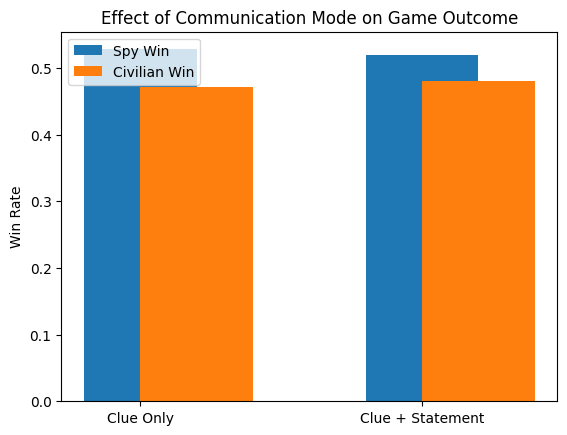

In [1]:
import matplotlib.pyplot as plt

modes = ["Clue Only", "Clue + Statement"]
spy_win = [0.528, 0.52]   # replace with your values
civilian_win = [0.472, 0.48]

x = range(len(modes))

plt.bar(x, spy_win, width=0.4, label='Spy Win', align='center')
plt.bar(x, civilian_win, width=0.4, label='Civilian Win', align='edge')

plt.xticks(x, modes)
plt.ylabel("Win Rate")
plt.title("Effect of Communication Mode on Game Outcome")
plt.legend()
plt.show()

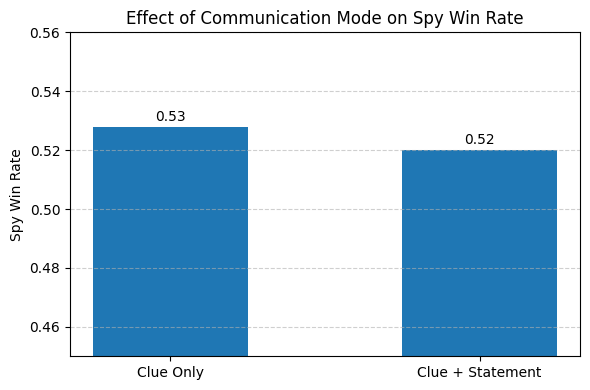

In [5]:
import matplotlib.pyplot as plt

# Data (replace if needed)
modes = ["Clue Only", "Clue + Statement"]
spy_win = [0.528, 0.52]  # your actual values

# Create figure
plt.figure(figsize=(6, 4))

# Plot bars
bars = plt.bar(modes, spy_win, width=0.5, color='#1f77b4')

# Y-axis range (zoomed for better visibility)
plt.ylim(0.45, 0.56)

# Labels and title
plt.ylabel("Spy Win Rate")
plt.title("Effect of Communication Mode on Spy Win Rate")

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.002,
             f"{height:.2f}", ha='center', fontsize=10)

# Clean layout
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# Show plot
plt.show()

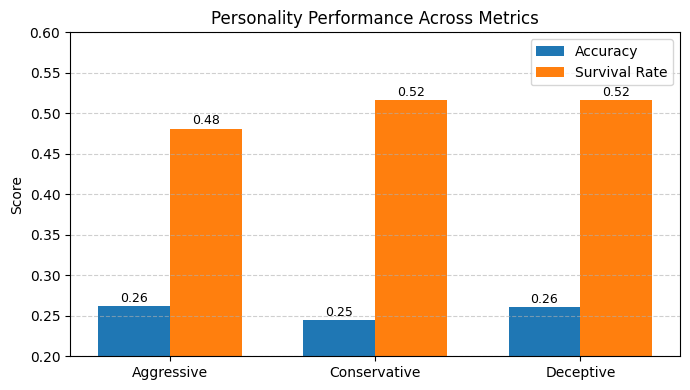

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Data
personalities = ["Aggressive", "Conservative", "Deceptive"]
accuracy = [0.2621, 0.2452, 0.2607]
survival = [0.4812, 0.5169, 0.5165]

x = np.arange(len(personalities))
width = 0.35

plt.figure(figsize=(7, 4))

# Bars
bars1 = plt.bar(x - width/2, accuracy, width, label='Accuracy', color='#1f77b4')
bars2 = plt.bar(x + width/2, survival, width, label='Survival Rate', color='#ff7f0e')

# Labels
plt.xticks(x, personalities)
plt.ylabel("Score")
plt.title("Personality Performance Across Metrics")

# Zoomed Y-axis for better comparison
plt.ylim(0.2, 0.6)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2,
                 height + 0.005,
                 f"{height:.2f}",
                 ha='center', fontsize=9)

# Grid + legend
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.show()

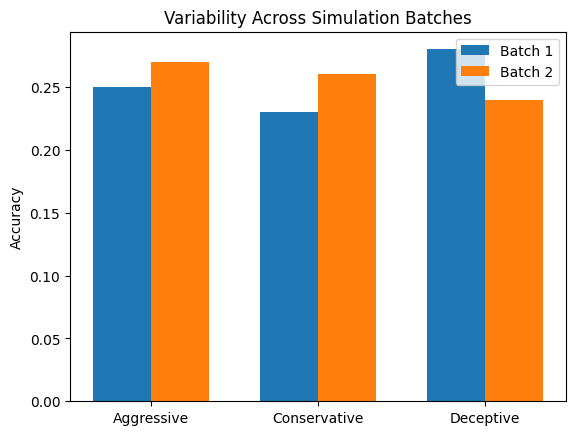

In [7]:
import numpy as np

personalities = ["Aggressive", "Conservative", "Deceptive"]

batch1 = [0.25, 0.23, 0.28]
batch2 = [0.27, 0.26, 0.24]

x = np.arange(len(personalities))
width = 0.35

plt.bar(x - width/2, batch1, width, label='Batch 1')
plt.bar(x + width/2, batch2, width, label='Batch 2')

plt.xticks(x, personalities)
plt.ylabel("Accuracy")
plt.title("Variability Across Simulation Batches")
plt.legend()
plt.show()